# Lab 09: Assignment 2 Tutorial

In Assignment 1, we followed a wave packet in a harmonic well. Now put it in the right-hand well of a double-well potential.

A classical particle below the barrier cannot cross. What will the quantum probability density do, and how can we tell when it has reached the left well?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# if you're curious, this is to change default formatting  
# make plots look good in the slideshow format.
plt.rcParams.update({"font.size": 13,
    "figure.figsize": (6.2, 3.3), "figure.dpi": 100,
    "figure.constrained_layout.use": True})

## Put the wavefunction on a grid

We will store one complex amplitude at each position. Use $m=\hbar=1$ and 600 intervals on $[-4,4]$.

In [3]:
# coding culture: we tend to use capital letters when want to define 
# immutable constants that will be used throughout a whole script.
ALPHA = 0.4
HBAR = 1
BOXSIZE = 8
ND = 600
DELTAX = BOXSIZE / ND
XMIN = 1 / np.sqrt(ALPHA)
x = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, ND + 1)
print("Positions:", x.size, "Spacing:", DELTAX)

Positions: 601 Spacing: 0.013333333333333334


There are 601 positions and 600 intervals. The spacing $\Delta x$ will weight our spatial sums.

## Two wells and a barrier

$$
V(x)=\alpha x^4-2x^2+\frac{1}{\alpha}.
$$

We'll use $\alpha=0.4$ here. Use your assigned value in the homework.

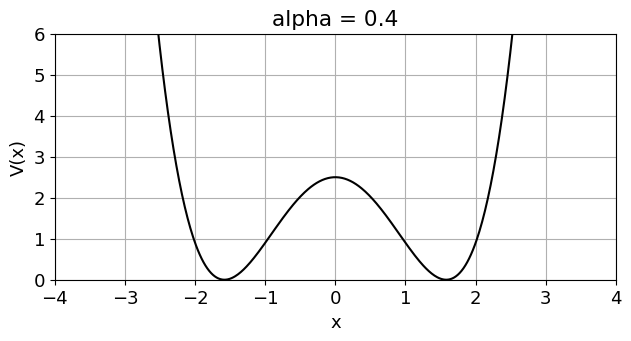

In [27]:
# and then we use lowercase for more generic variables.
def V(x, alpha):
    return alpha * x**4 - 2 * x**2 + 1 / alpha

alpha_view = ALPHA
fig, ax = plt.subplots()
ax.plot(x, V(x, alpha_view), color="black")
ax.set(xlabel="x", ylabel="V(x)",
       xlim=(-4, 4), ylim=(0, 6),
       title=f"alpha = {alpha_view}")
ax.grid(True) 
plt.show()

Raise `alpha_view` to 0.6. How do the barrier and separation change? This changes only the preview; the evolution uses `ALPHA`.

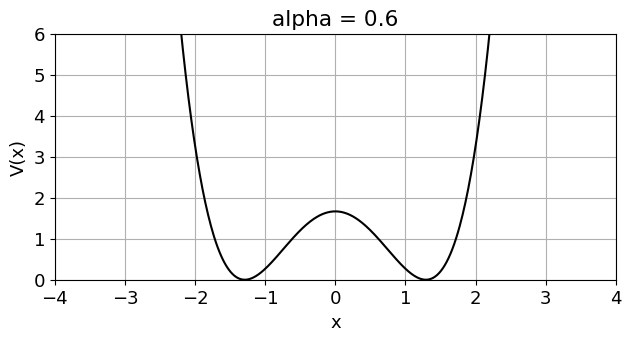

In [25]:
# and then we use lowercase for more generic variables
def V(x, alpha):
    return alpha * x**4 - 2 * x**2 + 1 / alpha

alpha_view = .6 # <==========================================
fig, ax = plt.subplots()
ax.plot(x, V(x, alpha_view), color="black")
ax.set(xlabel="x", ylabel="V(x)",
       xlim=(-4, 4), ylim=(0, 6),
       title=f"alpha = {alpha_view}")
ax.grid(True) 
plt.show()

## Near each minimum

The potential is locally quadratic (first order taylor expansion):

$$
V_\pm(x)=4(x\mp x_{\min})^2,
$$

with $x_{\min}=1/\sqrt{\alpha}$

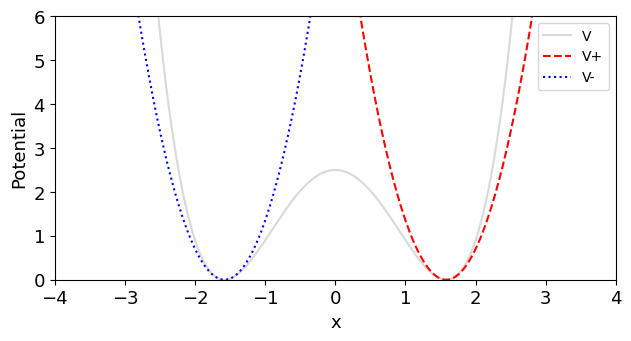

In [33]:
alpha_view = ALPHA # let's not forget to turn this back to our universal CONSTANT

def V_plus(x, alpha): 
    return 4 * (x - 1 / np.sqrt(alpha))**2
def V_minus(x, alpha):
    return 4 * (x + 1 / np.sqrt(alpha))**2

def plot_potentials(ax, v_color, posv_color, negv_color):
    ax.plot(x, V(x, ALPHA), color=v_color)
    ax.plot(x, V_plus(x, ALPHA), "--", color=posv_color)
    ax.plot(x, V_minus(x, ALPHA), ":", color=negv_color)
    ax.set(ylabel="Potential", ylim=(0, 6),
           zorder=0)
    ax.legend(["V", "V+", "V-"],
              loc="upper right", fontsize=10)
    
x_window = (-4, 4)
fig, ax = plt.subplots()

plot_potentials(ax, v_color = ('black', 0.15), posv_color='red', negv_color='blue') # can you guess how to colors work here?
ax.set(xlabel="x", xlim=x_window)
plt.show()

Where does the approximation fail?

## The initial wavefunction

We're approximating both wells locally as harmonic, so we might as well approximate the state as a ground state oscillator, with $\omega=2\sqrt{2}$:

$$
\psi(x)=\left(\frac{\omega}{\pi}\right)^{1/4}
\exp\left[-\frac{\omega}{2}(x-x_c)^2\right],
$$

which remember is just a gaussian.

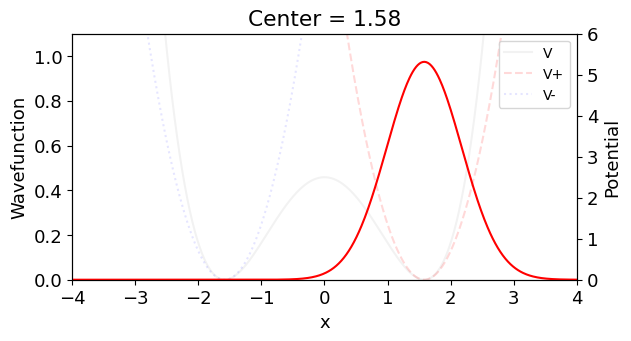

In [43]:
OMEGA = np.sqrt(8)
def func_psi_0(x, x_start):
    return (OMEGA / np.pi)**0.25 * np.exp(
        -OMEGA * (x - x_start)**2 / (2 * HBAR))

psi_0 = func_psi_0(x, XMIN)
center = XMIN

fig, ax = plt.subplots()
ax.plot(x, func_psi_0(x, center), color='red')
ax.set(xlabel="x", ylabel="Wavefunction",
       zorder=1, xlim=(-4, 4), ylim=(0, 1.1),
       title=f"Center = {center:.2f}")

ax.patch.set_visible(False)
plot_potentials(ax.twinx(), v_color = ('black', .05), posv_color=('red', .15), negv_color=('blue', .1))
plt.show()

## Why can a localized state move?

The full potential has even and odd energy eigenstates (state functions). 
Our right-well Gaussian is neither.
So to actually allow it to physically make sense globally, 
we need to construct even and odd versions of the state.

$$
\psi_{\mathrm S}=\frac{\psi_++\psi_-}{\sqrt{2}},\qquad
\psi_{\mathrm A}=\frac{\psi_+-\psi_-}{\sqrt{2}}.
$$

### Even/odd function refresher
hey chat, put a refresher here. just showing that if you swap the P/M functions, the even part stays positive, and the odd part gains a negative.

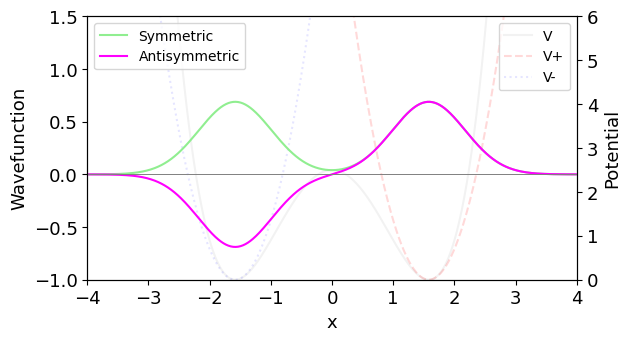

In [53]:
psi_plus = func_psi_0(x, XMIN)
psi_minus = func_psi_0(x, -XMIN)
psi_S = (psi_plus + psi_minus) / np.sqrt(2)
psi_A = (psi_plus - psi_minus) / np.sqrt(2)

fig, ax = plt.subplots()
ax.plot(x, psi_S, label="Symmetric", color='lightgreen')
ax.plot(x, psi_A, label="Antisymmetric", color='magenta')
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="x", ylabel="Wavefunction",
       zorder=1, xlim=(-4, 4), ylim=(-1, 1.5))
ax.legend(loc="upper left", fontsize=10)
ax.patch.set_visible(False)
plot_potentials(ax.twinx(), v_color = ('black', .05), posv_color=('red', .15), negv_color=('blue', .1))
plt.show()

These approximate the lowest even and odd states. Different phase rates allow their superposition to change its density. Which combination has a node at the barrier?

## Advance the amplitudes

$$
\tilde{\mathcal K}(x_b,\Delta t;x_a,0)=
\exp\left[i\left(\frac{(x_b-x_a)^2}{2\Delta t}
-V\left(\frac{x_a+x_b}{2}\right)\Delta t\right)\right].
$$

In [57]:
def func_K(x_a, x_b, dt, alpha):
    kinetic = 0.5 * (x_b - x_a)**2 / dt
    potential = V((x_a + x_b) / 2, alpha) * dt
    return np.exp(1j * (kinetic - potential))

## From the propagator to the next state

Add the complex amplitudes from every starting position. On the grid, the integral becomes a weighted sum:

$$
\begin{aligned}
\psi(x_b,t+\Delta t)&\approx\int \mathcal K(x_b,x_a;\Delta t)\psi(x_a,t)\,dx_a,\\
\psi_i(t+\Delta t)&\approx\Delta x\sum_j K_{ij}\psi_j(t).
\end{aligned}
$$

Why do we add the amplitudes before taking the absolute square?

## Build the matrix

Each column starts at one position; each row arrives at one position. Use the assignment's $\Delta t=\pi/128$ for the evolution.

In [59]:
DELTAT = np.pi / 128
K_dt = np.zeros((ND + 1, ND + 1), dtype=np.complex64)

for i in range(ND + 1):
    for j in range(ND + 1):
        K_dt[i, j] = func_K(x[j], x[i], DELTAT, ALPHA)

print("Kernel shape:", K_dt.shape)

Kernel shape: (601, 601)


For a fixed starting position $j$, which slice gives all of its destination amplitudes?

## Take a step and inspect it

The grid sum is a matrix–vector product. Normalize because our kernel omits the scalar prefactor.

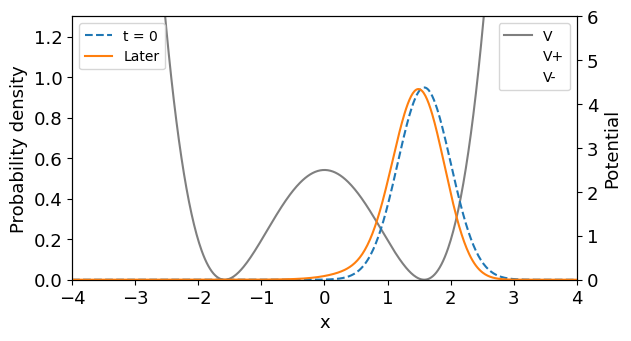

In [62]:
def step(state, kernel, dx):
    updated = dx * (kernel @ state)
    norm = dx * np.sum(np.abs(updated)**2)
    return updated / np.sqrt(norm)
    
steps_view = 20
psi_view = psi_0.copy()
for _ in range(steps_view):
    psi_view = step(psi_view, K_dt, DELTAX)
    
fig, ax = plt.subplots()
ax.plot(x, np.abs(psi_0)**2, "--", label="t = 0")
ax.plot(x, np.abs(psi_view)**2, label="Later")
ax.set(xlabel="x", ylabel="Probability density",
       zorder=1, xlim=(-4, 4), ylim=(0, 1.3))
ax.legend(loc="upper left", fontsize=10)
ax.patch.set_visible(False)

plot_potentials(ax.twinx(), v_color = ('black', .5), posv_color=('red', 0), negv_color=('blue', 0))
plt.show()

Try `steps_view = 100`. Does the shape change? Normalization keeps total probability at one; it does not establish accuracy.

## Follow the motion

Run to $T=20\pi$. The mean is the probability-weighted average of position:

$$
\langle x\rangle(t)\approx\Delta x\sum_i x_i|\psi(x_i,t)|^2.
$$

In [ ]:
T0 = 20 * np.pi
NT = int(T0 / DELTAT)
t = np.arange(NT + 1) * DELTAT
psi = [psi_0]
for _ in range(NT):
    psi.append(step(psi[-1], K_dt, DELTAX))
prob = np.abs(np.asarray(psi))**2
x_bar = DELTAX * (prob @ x)

fig, ax = plt.subplots()
ax.plot(t, x_bar)
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Time", ylabel="Mean position",
       xlim=(0, t[-1]))
plt.show()

Find the first broad minimum, rather than one of the faster fluctuations. Has most of the probability reached the left well?

## Check what the mean is telling us

In [ ]:
time_view = 0.0
n = np.argmin(np.abs(t - time_view))
fig, ax = plt.subplots()
ax.plot(x, prob[n])
ax.set(xlabel="x", ylabel="Probability density",
       zorder=1, xlim=(-4, 4),
       ylim=(0, 1.1 * prob.max()),
       title=f"t = {t[n]:.3f}")
ax.patch.set_visible(False)
plot_potentials(ax.twinx())
plt.show()

Set `time_view` near that minimum. Is the probability transferred or split? Would $\langle x\rangle=0$ mean the particle is at the barrier?

## How long did the first trip take?

Give the time and mean position at the first major minimum. Use the density at that time to explain whether most of the probability has reached the left well.

For your assigned $\alpha$, check that the run is long enough to see the transfer and return.

Assignment 2 is due Monday, November 2.

Run cells in order. Shift+Enter selects the discussion question on the same slide, leaving the result visible. Click the code cell to edit and run it again; Ctrl+Enter runs without changing the selected cell. After changing `ALPHA`, rerun from the setup onward. The preview controls redraw their own plots; use `ALPHA` in the setup to change the evolution.